## Imputation Results and Analysis

### **0. Setting Up**
- Importing libraries 
- <span style="color:red">**Make own libraries that include the python files I require AND sort out directories issue**</span>

In [1]:
# Change working directory
import os
tissue_path = os.path.join(os.getcwd(), "TISSUE")
os.chdir(tissue_path)

# import packages
import tissue.main, tissue.downstream
import tissue.SpaGE.main as sp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objs as go
from plotly.subplots import make_subplots
import scanpy as sc
import anndata as ad
import scipy.stats as st
from statsmodels.stats.multitest import multipletests
from sklearn.metrics import mean_squared_error
from sklearn.metrics import auc
from sklearn.metrics import mean_squared_error, jaccard_score
from skimage.metrics import structural_similarity as ssim
import torch
from torch.nn.functional import softmax, cosine_similarity, sigmoid
import tangram as tg
from tqdm import tqdm


### **1. Load in processed anndata files and algorithm predictions**

**(i) Load in processed h5ad files**

In [2]:
RNAseq_adata = sc.read('/Users/Amith/Documents/Documents – Viji’s MacBook Pro/Work/LIDo PhD/Year 1/Rotation 2/Project Work/Code/Imputation_Comparison/processed_gene_data/RNA_seq_adata_processed_d2.h5ad')
adata = sc.read('/Users/Amith/Documents/Documents – Viji’s MacBook Pro/Work/LIDo PhD/Year 1/Rotation 2/Project Work/Code/Imputation_Comparison/processed_gene_data/adata_processed_d2.h5ad')

**(ii) Load in algorithm predictions and annotate anndata**
- Format: cells (numbers) x genes (names LC)

In [4]:
# Load tangram and spage predictions
tangram_preds = pd.read_csv('/Users/Amith/Documents/Documents – Viji’s MacBook Pro/Work/LIDo PhD/Year 1/Rotation 2/Project Work/Code/Imputation_Comparison/predictions/tissue_tangram_preds_d2.csv', index_col=0)
spage_preds = pd.read_csv('/Users/Amith/Documents/Documents – Viji’s MacBook Pro/Work/LIDo PhD/Year 1/Rotation 2/Project Work/Code/Imputation_Comparison/predictions/tissue_spage_preds_d2.csv', index_col=0)

# Store tangram predictions in adata
tangram_preds.index = adata.obs_names
adata.obsm['tangram_predictions'] = tangram_preds

# Store spage predictions in adata
spage_preds.index = adata.obs_names
adata.obsm['spage_predictions'] = spage_preds

**(iii) Extract actual (normalised) gene expression data for comparison**

In [ ]:
actual_gene_expression_d2 

,acin1,acsl4,actg1,actn4,add2,alcam,aldoc,amigo2,ankrd6,apc,...,wfs1,wsb1,xpc,ybx1,yjefn3,zbtb20,zbtb38,zc3h18,zcchc12,zfp777
cell,,,,,,,,,,,,,,,,,,,,,
1818618800005100006,1.883592,0.000000,1.856733,1.627505,0.000000,1.674271,0.000000,1.843140,0.000000,1.380747,...,0.000000,0.000000,0.000000,1.218839,0.000000,1.221655,1.556568,1.590947,0.0,0.000000
1818618800005100007,2.127254,0.000000,2.093238,1.801487,0.000000,1.982393,0.000000,0.000000,0.000000,1.695861,...,0.000000,0.000000,0.000000,1.517872,1.915044,1.269287,1.609716,0.000000,0.0,1.625477
1818618800005100008,2.092227,0.000000,2.134241,1.728412,0.000000,2.271369,0.000000,0.000000,0.000000,1.973125,...,1.882501,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,1.898766
1818618800005100011,0.000000,1.538370,2.083500,2.051147,0.000000,0.000000,0.000000,1.783572,0.000000,1.703147,...,0.000000,1.218279,0.000000,1.282376,0.000000,1.393439,0.000000,0.000000,0.0,1.632645
1818618800005100012,1.513712,0.000000,1.797295,1.909875,0.000000,0.000000,1.074939,1.824018,0.000000,0.000000,...,0.000000,1.364692,1.306619,1.588693,0.000000,1.067482,1.120777,1.415029,0.0,1.134070
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1818618800254200022,2.281479,0.000000,2.475022,2.299857,0.000000,0.000000,0.000000,2.238593,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.084752,0.000000,0.0,0.000000
1818618800274100077,1.779754,0.965560,1.810208,1.901050,0.000000,1.760247,0.000000,1.568461,0.000000,1.627916,...,1.257723,0.000000,1.205787,1.358042,0.000000,1.521147,1.615023,1.330574,0.0,1.040628
1818618800274100082,1.682862,1.093094,1.618356,1.782696,0.710510,1.979574,0.000000,0.845345,0.792052,1.396260,...,0.000000,0.000000,1.517515,1.336070,1.111046,1.103155,1.422991,1.189907,0.0,1.173473


### **2. Metric Comparisons and Analysis**

**(i) Metric dataframe generation**
- Compute Pearson, Spearman, RMSE, Cosine Similarity, Jaccard Similiarity and SSIM for both methods (for Tangram then SpaGE)

In [24]:
def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

In [25]:
### For Tangram
# Step 1: Get common genes
common_genes = tangram_preds.columns.intersection(actual_gene_expression.columns)

# Step 2: Compute metrics for each gene with progress bar
tangram_results = {}
for gene in tqdm(common_genes, desc="🔁 Computing gene metrics"):
    x = tangram_preds[gene]
    y = actual_gene_expression[gene]

    # Pearson and Spearman
    pearson_r, _ = st.pearsonr(x, y)
    spearman_r, _ = st.spearmanr(x, y)
    rmse_val = rmse(y, x)

    # Cosine similarity
    norm_x = np.linalg.norm(x)
    norm_y = np.linalg.norm(y)
    cosine_sim = np.nan if norm_x == 0 or norm_y == 0 else np.dot(x, y) / (norm_x * norm_y)

    # Jaccard similarity
    bin_x = (x > 0).astype(int)
    bin_y = (y > 0).astype(int)
    try:
        jaccard_sim = jaccard_score(bin_x, bin_y)
    except ValueError:
        jaccard_sim = np.nan

    # SSIM
    try:
        side = int(np.sqrt(len(x)))
        x_img = np.array(x[:side*side]).reshape(side, side)
        y_img = np.array(y[:side*side]).reshape(side, side)
        ssim_val = ssim(x_img, y_img, data_range=y_img.max() - y_img.min())
    except:
        ssim_val = np.nan

    tangram_results[gene] = {
        'pearson_r': pearson_r,
        'spearman_r': spearman_r,
        'RMSE': rmse_val,
        'cosine_sim': cosine_sim,
        'jaccard_sim': jaccard_sim,
        'ssim': ssim_val,
    }

# Step 3: Convert to DataFrame
tangram_metrics_df = pd.DataFrame.from_dict(tangram_results, orient='index')

🔁 Computing gene metrics:   0%|          | 0/296 [00:00<?, ?it/s]

🔁 Computing gene metrics: 100%|██████████| 296/296 [00:07<00:00, 37.01it/s]


In [26]:
### For SpaGE
# Step 1: Get common genes
common_genes = spage_preds.columns.intersection(actual_gene_expression.columns)

# Step 2: Compute metrics for each gene with progress bar
spage_results = {}
for gene in tqdm(common_genes, desc="🔁 Computing gene metrics"):
    x = spage_preds[gene]
    y = actual_gene_expression[gene]

    # Pearson and Spearman
    pearson_r, _ = st.pearsonr(x, y)
    spearman_r, _ = st.spearmanr(x, y)
    rmse_val = rmse(y, x)

    # Cosine similarity
    norm_x = np.linalg.norm(x)
    norm_y = np.linalg.norm(y)
    cosine_sim = np.nan if norm_x == 0 or norm_y == 0 else np.dot(x, y) / (norm_x * norm_y)

    # Jaccard similarity
    bin_x = (x > 0).astype(int)
    bin_y = (y > 0).astype(int)
    try:
        jaccard_sim = jaccard_score(bin_x, bin_y)
    except ValueError:
        jaccard_sim = np.nan

    # SSIM
    try:
        side = int(np.sqrt(len(x)))
        x_img = np.array(x[:side*side]).reshape(side, side)
        y_img = np.array(y[:side*side]).reshape(side, side)
        ssim_val = ssim(x_img, y_img, data_range=y_img.max() - y_img.min())
    except:
        ssim_val = np.nan

    spage_results[gene] = {
        'pearson_r': pearson_r,
        'spearman_r': spearman_r,
        'RMSE': rmse_val,
        'cosine_sim': cosine_sim,
        'jaccard_sim': jaccard_sim,
        'ssim': ssim_val,
    }

# Step 3: Convert to DataFrame
spage_metrics_df = pd.DataFrame.from_dict(spage_results, orient='index')

🔁 Computing gene metrics:   0%|          | 0/296 [00:00<?, ?it/s]

🔁 Computing gene metrics: 100%|██████████| 296/296 [00:07<00:00, 38.57it/s]


In [27]:
# Extract sparsity as DataFrames with explicit column names
df_sparsity_sp = pd.DataFrame(
    adata[:, common_genes].var["sparsity"]
).rename(columns={"sparsity": "sparsity_sp"})

df_sparsity_sc = pd.DataFrame(
    RNAseq_adata[:, common_genes].var["sparsity"]
).rename(columns={"sparsity": "sparsity_sc"})

# Merge the two sparsity DataFrames
df_sparsity = df_sparsity_sp.merge(
    df_sparsity_sc, left_index=True, right_index=True
)

# Calculate the difference
df_sparsity["sparsity_diff"] = np.abs(df_sparsity["sparsity_sp"] - df_sparsity["sparsity_sc"])

# Merge with the existing metrics
tangram_gene_metrics_df = tangram_metrics_df.merge(df_sparsity, left_index=True, right_index=True)
spage_gene_metrics_df = spage_metrics_df.merge(df_sparsity, left_index=True, right_index=True)

--- Statistical Summary of Tangram Performance Metrics ---
        pearson_r  spearman_r        RMSE  cosine_sim  jaccard_sim        ssim
count  296.000000  296.000000  296.000000  296.000000   296.000000  296.000000
mean     0.294072    0.237175    0.758215    0.813200     0.704792    0.110302
std      0.177948    0.205586    0.493164    0.156938     0.232045    0.116757
min     -0.209912   -0.318615    0.251345    0.197537     0.136442   -0.004130
25%      0.177055    0.100420    0.506771    0.738322     0.540033    0.023377
50%      0.280484    0.235450    0.626692    0.865506     0.771581    0.062045
75%      0.426777    0.396812    0.793439    0.939899     0.904130    0.166513
max      0.701349    0.655143    4.282517    0.990602     0.998676    0.518695


--- Statistical Summary of SpaGE Performance Metrics ---
        pearson_r  spearman_r        RMSE  cosine_sim  jaccard_sim        ssim
count  296.000000  296.000000  296.000000  296.000000   296.000000  296.000000
mean     0.26

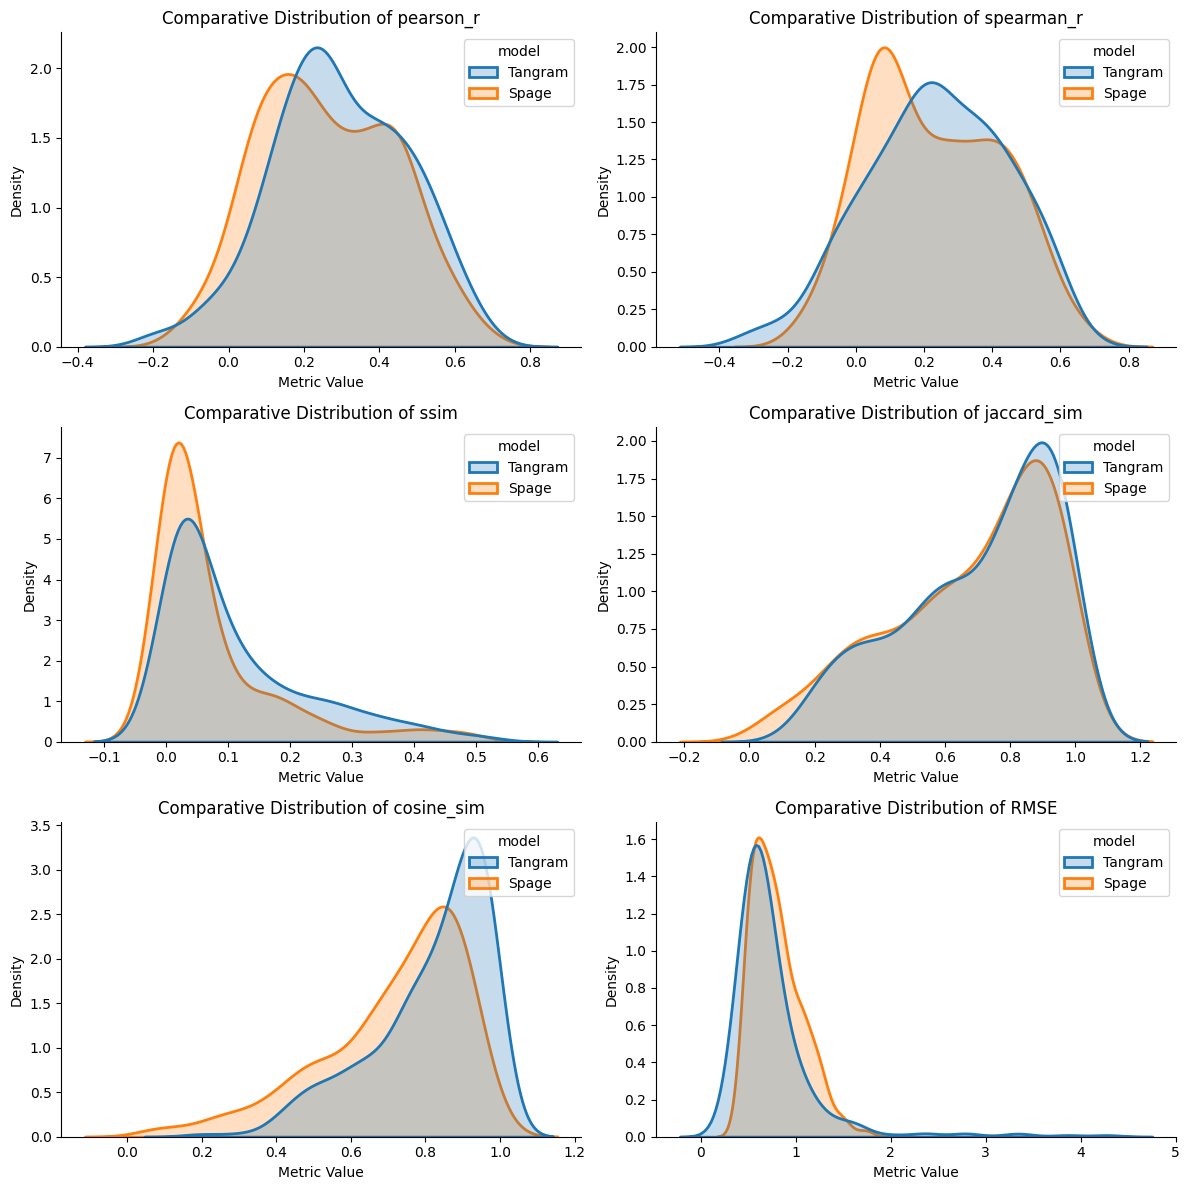

In [39]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# --- Analysis: Compare Tangram and SpaGE Performance Metric Distributions ---
# Assumes 'tangram_metrics_df' and 'spage_metrics_df' are pandas DataFrames from your previous calculations.

# 1. Combine DataFrames for unified plotting
# Add a 'model' column to each before concatenating
tangram_df_long = tangram_metrics_df.copy()
tangram_df_long['model'] = 'Tangram'

spage_df_long = spage_metrics_df.copy()
spage_df_long['model'] = 'Spage'

combined_metrics_df = pd.concat([tangram_df_long, spage_df_long], ignore_index=True)

# 2. Generate textual output with statistical summaries for both models
print("--- Statistical Summary of Tangram Performance Metrics ---")
# Drop columns that are entirely NaN before describing
print(tangram_metrics_df.dropna(axis=1, how='all').describe())

print("\n" + "="*60 + "\n")

print("--- Statistical Summary of SpaGE Performance Metrics ---")
print(spage_metrics_df.dropna(axis=1, how='all').describe())


# 3. Create the comparative visualizations
metrics_to_plot = ['pearson_r', 'spearman_r', 'ssim', 'jaccard_sim', 'cosine_sim', 'RMSE']
# Filter for metrics that exist and have valid data in the combined DataFrame
metrics_to_plot = [
    m for m in metrics_to_plot
    if m in combined_metrics_df.columns and combined_metrics_df[m].notna().any()
]

if metrics_to_plot:
    n_metrics = len(metrics_to_plot)
    n_cols = 2
    # Calculate rows needed, ensuring enough space
    n_rows = (n_metrics + n_cols - 1) // n_cols

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, n_rows * 4), squeeze=False)
    axes = axes.flatten() # Flatten to make looping easier regardless of grid size

    for i, metric in enumerate(metrics_to_plot):
        ax = axes[i]
        sns.kdeplot(
            data=combined_metrics_df,
            x=metric,
            hue='model',
            fill=True,
            common_norm=False, # Each model's density is normalized independently
            ax=ax,
            linewidth=2
        )
        ax.set_title(f'Comparative Distribution of {metric}')
        ax.set_xlabel('Metric Value')
        ax.set_ylabel('Density')

    # Hide any unused subplots
    for j in range(i + 1, len(axes)):
        axes[j].axis('off')

    sns.despine()
    plt.tight_layout()
    plt.show()
else:
    print("\nNo valid metrics with data were found to plot for comparison.")


#END

--- Correlation of Performance Metrics with Spatial Sparsity (sparsity_sp) ---

Tangram Model Correlations with sparsity_sp:
pearson_r     -0.001
spearman_r     0.081
ssim          -0.254
jaccard_sim   -1.000
cosine_sim    -0.985
Name: sparsity_sp, dtype: float64


SpaGE Model Correlations with sparsity_sp:
pearson_r     -0.001
spearman_r    -0.032
ssim          -0.173
jaccard_sim   -0.977
cosine_sim    -0.881
Name: sparsity_sp, dtype: float64


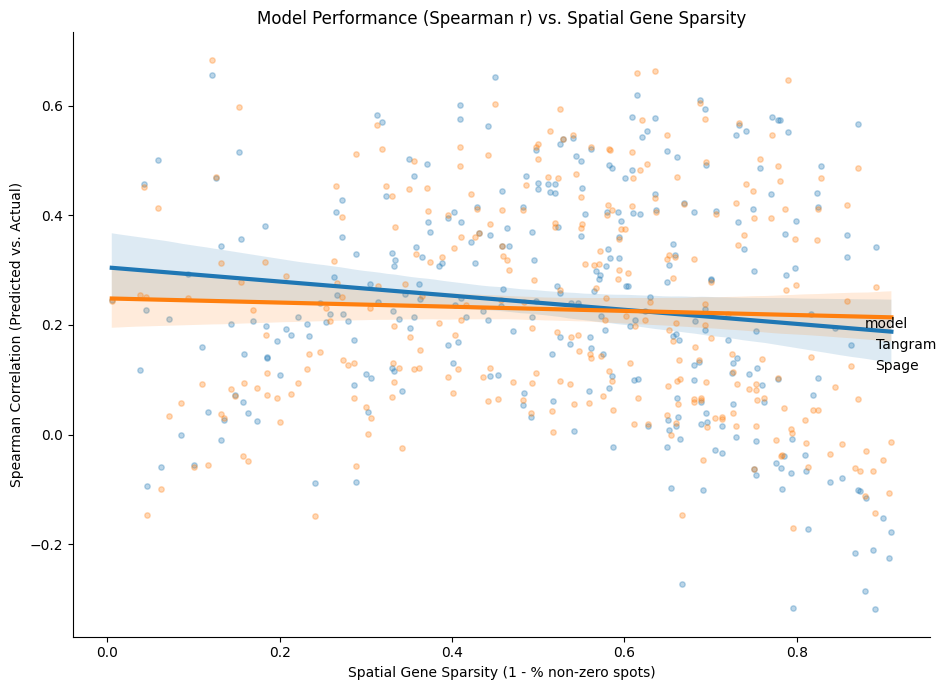

In [34]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# --- Analysis: Investigate Impact of Sparsity on Model Performance ---
# Assumes 'tangram_gene_metrics_df' and 'spage_gene_metrics_df' DataFrames exist.

# 1. Correlation Analysis (Textual Output)
metric_cols = ['pearson_r', 'spearman_r', 'ssim', 'jaccard_sim', 'cosine_sim']
sparsity_cols = ['sparsity_sp', 'sparsity_sc', 'sparsity_diff']

# Filter to ensure columns exist in the dataframe before calculating correlation
valid_tangram_cols = tangram_gene_metrics_df.columns.intersection(metric_cols + sparsity_cols)
tangram_corr = tangram_gene_metrics_df[valid_tangram_cols].corr(method='spearman')

valid_spage_cols = spage_gene_metrics_df.columns.intersection(metric_cols + sparsity_cols)
spage_corr = spage_gene_metrics_df[valid_spage_cols].corr(method='spearman')

print("--- Correlation of Performance Metrics with Spatial Sparsity (sparsity_sp) ---")
print("\nTangram Model Correlations with sparsity_sp:")
# Select correlations of performance metrics with just spatial sparsity
print(tangram_corr.loc[metric_cols, 'sparsity_sp'].dropna().round(3))

print("\n" + "="*60 + "\n")

print("SpaGE Model Correlations with sparsity_sp:")
print(spage_corr.loc[metric_cols, 'sparsity_sp'].dropna().round(3))


# 2. Visualisation of Performance vs. Sparsity
# Combine data for plotting
tangram_plot_df = tangram_gene_metrics_df[['spearman_r', 'sparsity_diff']].copy()
tangram_plot_df['model'] = 'Tangram'

spage_plot_df = spage_gene_metrics_df[['spearman_r', 'sparsity_diff']].copy()
spage_plot_df['model'] = 'Spage'

combined_plot_df = pd.concat([tangram_plot_df, spage_plot_df]).dropna()

# Create a scatter plot with regression lines for each model
# Using lmplot is convenient for this as it handles hue and regression automatically
g = sns.lmplot(
    data=combined_plot_df,
    x='sparsity_diff',
    y='spearman_r',
    hue='model',
    height=7,
    aspect=1.2,
    scatter_kws={'alpha': 0.3, 's': 15}, # Make points semi-transparent
    line_kws={'linewidth': 3}
)

# Formatting
g.set(
    title='Model Performance (Spearman r) vs. Spatial Gene Sparsity',
    xlabel='Spatial Gene Sparsity (1 - % non-zero spots)',
    ylabel='Spearman Correlation (Predicted vs. Actual)'
)
plt.tight_layout()
plt.show()


#END

--- Summary Statistics for Plotted Variables ---

Tangram Model:
       spearman_r  sparsity_sc  sparsity_sp  sparsity_diff
count     296.000      296.000      296.000        296.000
mean        0.237        0.816        0.295          0.525
std         0.206        0.172        0.232          0.221
min        -0.319        0.062        0.001          0.005
25%         0.100        0.752        0.096          0.357
50%         0.235        0.862        0.228          0.560
75%         0.397        0.935        0.460          0.694
max         0.655        0.999        0.864          0.910


SpaGE Model:
       spearman_r  sparsity_sc  sparsity_sp  sparsity_diff
count     296.000      296.000      296.000        296.000
mean        0.228        0.816        0.295          0.525
std         0.194        0.172        0.232          0.221
min        -0.171        0.062        0.001          0.005
25%         0.067        0.752        0.096          0.357
50%         0.208        0.862     

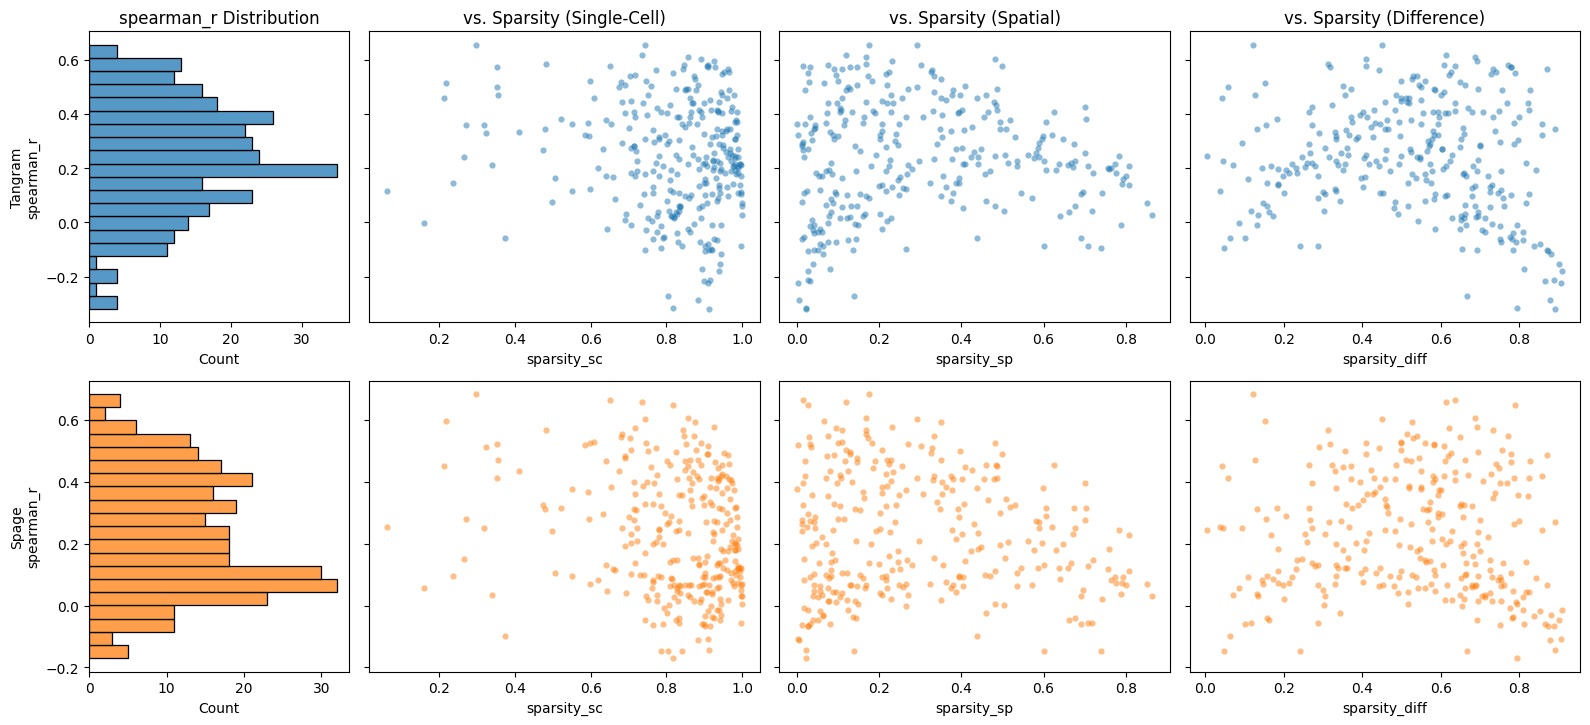

In [30]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# --- Analysis: Comparative Performance vs. Sparsity Breakdown (Revised) ---
# Assumes 'tangram_gene_metrics_df' and 'spage_gene_metrics_df' DataFrames exist.

# 1. Prepare data and define variables
model_data = {
    'Tangram': tangram_gene_metrics_df,
    'Spage': spage_gene_metrics_df
}
colors = sns.color_palette()
performance_metric = 'spearman_r'
sparsity_metrics = ['sparsity_sc', 'sparsity_sp', 'sparsity_diff']
cols_to_describe = [performance_metric] + sparsity_metrics

# 2. Textual Output: Summary Statistics
print("--- Summary Statistics for Plotted Variables ---")

print("\nTangram Model:")
# Ensure columns exist before describing to avoid errors
tangram_stats = tangram_gene_metrics_df.get(cols_to_describe)
if tangram_stats is not None:
    print(tangram_stats.describe().round(3))
else:
    print("One or more expected columns not found for Tangram.")

print("\n" + "="*60 + "\n")

print("SpaGE Model:")
spage_stats = spage_gene_metrics_df.get(cols_to_describe)
if spage_stats is not None:
    print(spage_stats.describe().round(3))
else:
    print("One or more expected columns not found for SpaGE.")

# 3. Create the 2x4 grid of plots
fig, axes = plt.subplots(2, 4, figsize=(16, 8), sharey='row', gridspec_kw={'width_ratios': [1, 1.5, 1.5, 1.5]})

# --- Titles ---
col_titles = [f'{performance_metric} Distribution', 'vs. Sparsity (Single-Cell)', 'vs. Sparsity (Spatial)', 'vs. Sparsity (Difference)']
for ax, title in zip(axes[0], col_titles):
    ax.set_title(title)

# --- Loop through models to populate the plot grid ---
for i, (model_name, df) in enumerate(model_data.items()):
    ax_row = axes[i]
    model_color = colors[i]
    df_clean = df.dropna(subset=cols_to_describe)

    # Plot 1: Horizontal Histogram of the performance score
    sns.histplot(y=df_clean[performance_metric], ax=ax_row[0], color=model_color, bins=20)
    ax_row[0].set_xlabel('Count')
    ax_row[0].set_ylabel(f'{model_name}\n{performance_metric}')

    # Plot 2: Score vs. Single-Cell Sparsity
    sns.scatterplot(data=df_clean, x='sparsity_sc', y=performance_metric, ax=ax_row[1], alpha=0.5, color=model_color, s=20, linewidth=0)
    ax_row[1].set_xlabel('sparsity_sc')

    # Plot 3: Score vs. Spatial Sparsity
    sns.scatterplot(data=df_clean, x='sparsity_sp', y=performance_metric, ax=ax_row[2], alpha=0.5, color=model_color, s=20, linewidth=0)
    ax_row[2].set_xlabel('sparsity_sp')

    # Plot 4: Score vs. Sparsity Difference
    sns.scatterplot(data=df_clean, x='sparsity_diff', y=performance_metric, ax=ax_row[3], alpha=0.5, color=model_color, s=20, linewidth=0)
    ax_row[3].set_xlabel('sparsity_diff')

# --- Final Formatting ---
# By not calling sns.despine(), we keep the top and right spines, creating a "box"
plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to prevent title overlap
plt.show()


#END

In [19]:
!pip install esda libpysal tqdm

Analysis of Results:
This plot is a key finding. It confirms our hypothesis with strong quantitative evidence:
Strong Positive Correlation: For both Tangram and SpaGE, there is a clear, strong positive relationship between a gene's spatial autocorrelation (Moran's I) and its imputation accuracy (Spearman's r). Genes whose expression is highly clustered (Moran's I > 0.2) are predicted with high accuracy. Genes with random or near-random spatial patterns (Moran's I near 0) are predicted poorly.
Identical Performance Profiles: The regression lines for Tangram and SpaGE are almost perfectly superimposed. This indicates that both models are equally dependent on the intrinsic spatial structure of a gene. Neither model shows a particular advantage in imputing genes with low spatial structure.
Conclusion: The "easiness" or "hardness" of imputing a gene is not an arbitrary property but is directly tied to its spatial predictability. Both models excel at reconstructing patterns that are already spatially coherent and struggle with patterns that are not.

--- Step 1: Building spatial weights matrix ---
Spatial weights matrix created successfully.

--- Step 2: Calculating Moran's I for each gene ---


Calculating Moran's I: 100%|██████████| 296/296 [00:55<00:00,  5.30it/s]



--- Step 3: Correlation Analysis ---
Correlation (Spearman) between Moran's I and Tangram Performance (spearman_r): 0.726
Correlation (Spearman) between Moran's I and SpaGE Performance (spearman_r): 0.741


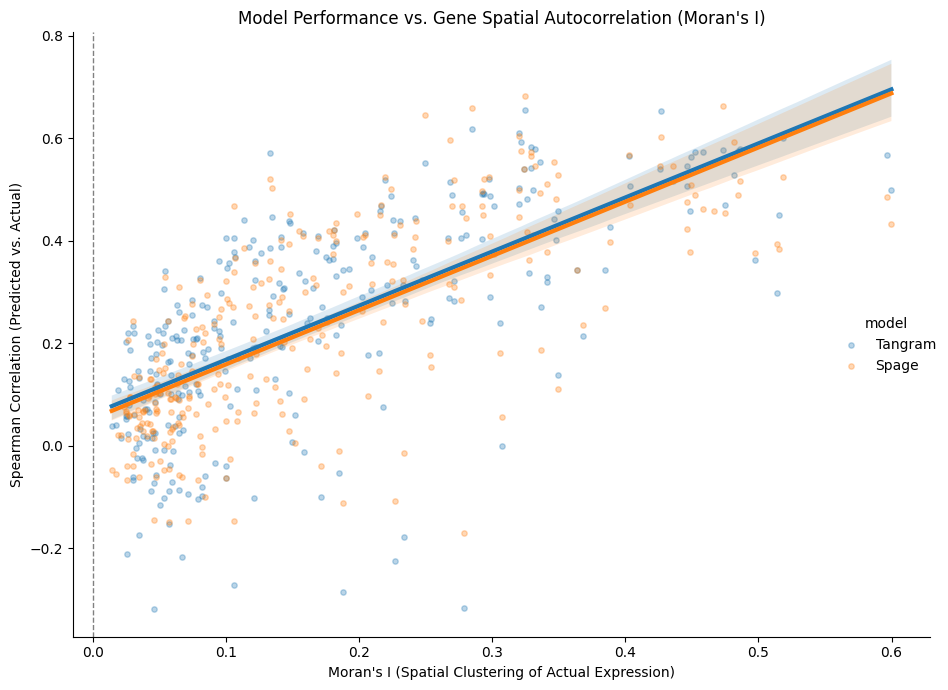

In [20]:
# --- You may need to run this in a separate cell first ---
# !pip install esda libpysal tqdm

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm
import libpysal.weights
from esda.moran import Moran

# --- Analysis: Relate Spatial Autocorrelation (Moran's I) to Model Performance ---
# Assumes 'adata' (filtered), 'tangram_gene_metrics_df', and 'spage_gene_metrics_df' exist.

# 1. Define Spatial Neighbors from adata coordinates
print("--- Step 1: Building spatial weights matrix ---")
coords = adata.obs[['center_x', 'center_y']].values
# Use k-nearest neighbors (k=6) to define local neighborhoods
try:
    W = libpysal.weights.KNN.from_array(coords, k=6)
    W.transform = 'r' # Row-standardize the weights
    print("Spatial weights matrix created successfully.")
except Exception as e:
    print(f"Error creating weights matrix: {e}")
    W = None

# 2. Calculate Moran's I for each gene's actual expression
moran_results = []
if W is not None:
    print("\n--- Step 2: Calculating Moran's I for each gene ---")
    # Ensure expression data is in a suitable format (numpy array)
    expression_matrix = adata.X.toarray() if hasattr(adata.X, 'toarray') else adata.X
    
    for i, gene in enumerate(tqdm(adata.var_names, desc="Calculating Moran's I")):
        gene_expression = expression_matrix[:, i]
        # Moran's I calculation
        mi = Moran(gene_expression, W, permutations=0) # Permutations set to 0 for speed, as we only need the 'I' value
        moran_results.append({'gene': gene, 'moran_I': mi.I})

moran_df = pd.DataFrame(moran_results)

# 3. Merge Moran's I scores with existing performance metrics
if not moran_df.empty:
    tangram_gene_metrics_df = tangram_gene_metrics_df.merge(moran_df, left_index=True, right_on='gene').set_index('gene')
    spage_gene_metrics_df = spage_gene_metrics_df.merge(moran_df, left_index=True, right_on='gene').set_index('gene')

    # 4. Generate Textual Output: Correlation between Moran's I and Spearman's r
    print("\n--- Step 3: Correlation Analysis ---")
    tangram_corr = tangram_gene_metrics_df[['spearman_r', 'moran_I']].corr(method='spearman').loc['spearman_r', 'moran_I']
    spage_corr = spage_gene_metrics_df[['spearman_r', 'moran_I']].corr(method='spearman').loc['spearman_r', 'moran_I']
    print(f"Correlation (Spearman) between Moran's I and Tangram Performance (spearman_r): {tangram_corr:.3f}")
    print(f"Correlation (Spearman) between Moran's I and SpaGE Performance (spearman_r): {spage_corr:.3f}")

    # 5. Visualize Performance vs. Moran's I
    # Combine data for plotting
    tangram_plot_df = tangram_gene_metrics_df[['spearman_r', 'moran_I']].copy()
    tangram_plot_df['model'] = 'Tangram'
    spage_plot_df = spage_gene_metrics_df[['spearman_r', 'moran_I']].copy()
    spage_plot_df['model'] = 'Spage'
    combined_plot_df = pd.concat([tangram_plot_df, spage_plot_df]).dropna()

    g = sns.lmplot(
        data=combined_plot_df,
        x='moran_I',
        y='spearman_r',
        hue='model',
        height=7,
        aspect=1.2,
        scatter_kws={'alpha': 0.3, 's': 15},
        line_kws={'linewidth': 3}
    )
    g.set(
        title="Model Performance vs. Gene Spatial Autocorrelation (Moran's I)",
        xlabel="Moran's I (Spatial Clustering of Actual Expression)",
        ylabel="Spearman Correlation (Predicted vs. Actual)"
    )
    plt.axvline(0, color='grey', linestyle='--', linewidth=1)
    plt.tight_layout()
    plt.show()
else:
    print("Could not proceed with analysis as Moran's I could not be calculated.")

#END

--- Step 1: Building spatial weights matrix ---
Spatial weights matrix created successfully.

--- Step 2: Calculating Moran's I for each gene ---


Calculating Moran's I: 100%|██████████| 296/296 [00:57<00:00,  5.11it/s]



--- Step 3: Correlation Analysis (Abundant Genes Only) ---
Correlation (Spearman) between Moran's I and Tangram Performance (sparsity_sp < 0.25): 0.710
Correlation (Spearman) between Moran's I and SpaGE Performance (sparsity_sp < 0.25): 0.737


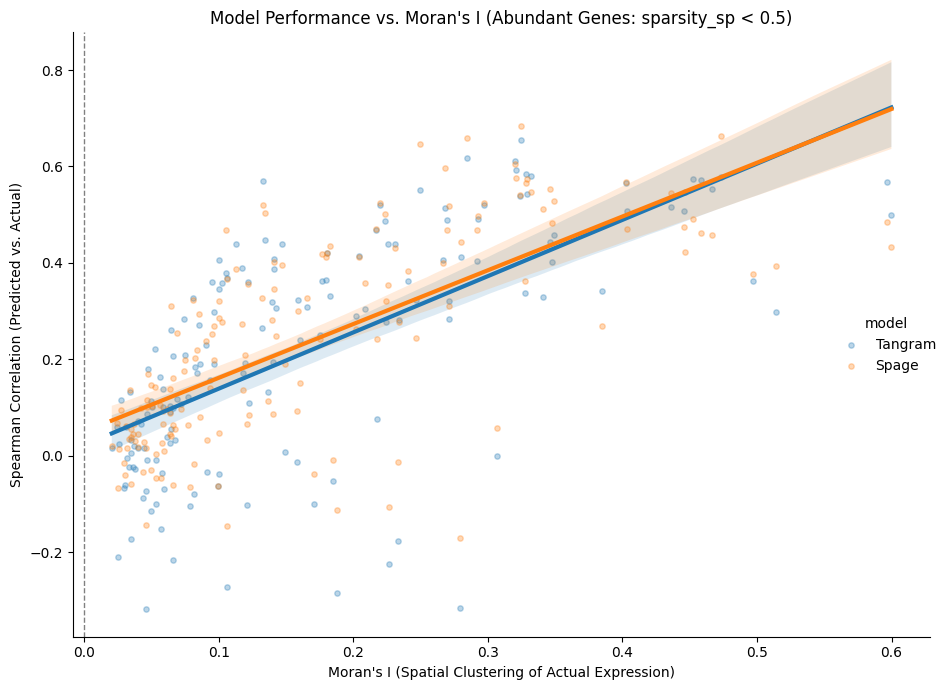

In [38]:
# --- You may need to run this in a separate cell first ---
# !pip install esda libpysal tqdm

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm
import libpysal.weights
from esda.moran import Moran

# --- Analysis: Moran's I vs Performance (Only for Abundant Genes) ---
# Assumes 'adata' (filtered), 'tangram_gene_metrics_df', and 'spage_gene_metrics_df' exist.

# 1. Define Spatial Neighbors from adata coordinates
print("--- Step 1: Building spatial weights matrix ---")
coords = adata.obs[['center_x', 'center_y']].values
# Use k-nearest neighbors (k=6) to define local neighborhoods
try:
    W = libpysal.weights.KNN.from_array(coords, k=6)
    W.transform = 'r'  # Row-standardise the weights
    print("Spatial weights matrix created successfully.")
except Exception as e:
    print(f"Error creating weights matrix: {e}")
    W = None

# 2. Calculate Moran's I for each gene's actual expression
moran_results = []
if W is not None:
    print("\n--- Step 2: Calculating Moran's I for each gene ---")
    expression_matrix = adata.X.toarray() if hasattr(adata.X, 'toarray') else adata.X

    for i, gene in enumerate(tqdm(adata.var_names, desc="Calculating Moran's I")):
        gene_expression = expression_matrix[:, i]
        mi = Moran(gene_expression, W, permutations=0)
        moran_results.append({'gene': gene, 'moran_I': mi.I})

moran_df = pd.DataFrame(moran_results)

# 3. Merge Moran's I with existing metrics, then filter to genes with sparsity_sp < 0.5
if not moran_df.empty:
    # Merge
    tangram_merged = tangram_gene_metrics_df.merge(moran_df, left_index=True, right_on='gene').set_index('gene')
    spage_merged = spage_gene_metrics_df.merge(moran_df, left_index=True, right_on='gene').set_index('gene')

    # Filter
    tangram_filtered = tangram_merged.query('sparsity_sp < 0.25')[['spearman_r', 'moran_I']].dropna()
    tangram_filtered['model'] = 'Tangram'

    spage_filtered = spage_merged.query('sparsity_sp < 0.25')[['spearman_r', 'moran_I']].dropna()
    spage_filtered['model'] = 'Spage'

    # Combine
    filtered_combined_plot_df = pd.concat([tangram_filtered, spage_filtered])

    # 4. Correlation output
    print("\n--- Step 3: Correlation Analysis (Abundant Genes Only) ---")
    tangram_corr = tangram_filtered[['spearman_r', 'moran_I']].corr(method='spearman').loc['spearman_r', 'moran_I']
    spage_corr = spage_filtered[['spearman_r', 'moran_I']].corr(method='spearman').loc['spearman_r', 'moran_I']
    print(f"Correlation (Spearman) between Moran's I and Tangram Performance (sparsity_sp < 0.25): {tangram_corr:.3f}")
    print(f"Correlation (Spearman) between Moran's I and SpaGE Performance (sparsity_sp < 0.25): {spage_corr:.3f}")

    # 5. Visualisation
    g = sns.lmplot(
        data=filtered_combined_plot_df,
        x='moran_I',
        y='spearman_r',
        hue='model',
        height=7,
        aspect=1.2,
        scatter_kws={'alpha': 0.3, 's': 15},
        line_kws={'linewidth': 3}
    )
    g.set(
        title="Model Performance vs. Moran's I (Abundant Genes: sparsity_sp < 0.5)",
        xlabel="Moran's I (Spatial Clustering of Actual Expression)",
        ylabel="Spearman Correlation (Predicted vs. Actual)"
    )
    plt.axvline(0, color='grey', linestyle='--', linewidth=1)
    plt.tight_layout()
    plt.show()
else:
    print("Could not proceed with analysis as Moran's I could not be calculated.")

#END


--- AUC-Based Performance Summary ---

Tangram Model:
  avg_pearson_r: 0.2941
  sparsity_weighted_score: 0.2982
  auc_score: 0.2420


SpaGE Model:
  avg_pearson_r: 0.2616
  sparsity_weighted_score: 0.2660
  auc_score: 0.2147


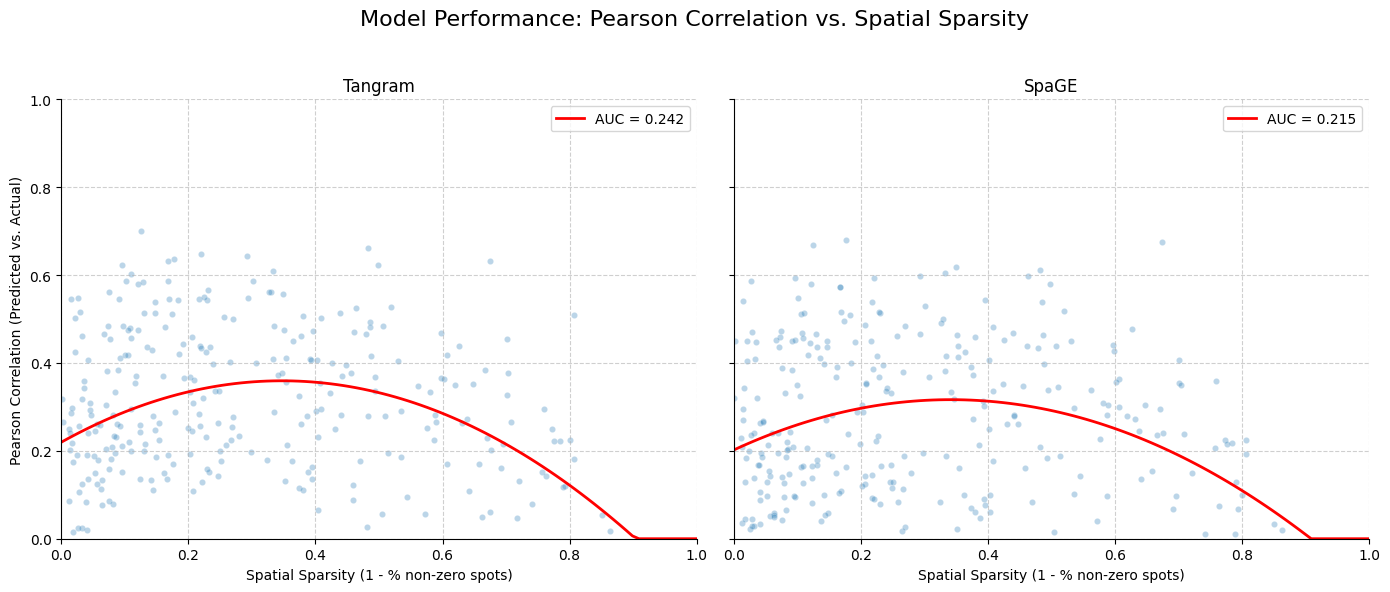

In [21]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import auc

# --- User-Provided Function: eval_metric ---
# (Included here for a self-contained, runnable script)
def eval_metric(df_metrics):
    """
    Compute metrics on given test_genes set for evaluation.
    This version uses 'pearson_r' and 'sparsity_sp'.
    """
    shared_genes = df_metrics.index

    # Ensure required columns exist
    if not all(col in df_metrics.columns for col in ["pearson_r", "sparsity_sp"]):
        raise ValueError("Input DataFrame must contain 'pearson_r' and 'sparsity_sp' columns.")

    test_gene_scores = df_metrics.loc[shared_genes]["pearson_r"]
    test_gene_sparsity_sp = df_metrics.loc[shared_genes]["sparsity_sp"]
    test_score_avg = test_gene_scores.mean()

    test_score_sps_sp_g2 = np.sum(
        (test_gene_scores * (1 - test_gene_sparsity_sp))
        / (1 - test_gene_sparsity_sp).sum()
    )

    xs = list(test_gene_sparsity_sp)
    ys = list(test_gene_scores)
    pol_deg = 2
    pol_cs = np.polyfit(xs, ys, pol_deg)
    pol = np.poly1d(pol_cs)

    pol_xs = np.linspace(0, 1, 100) # Increased points for a smoother curve
    pol_ys = pol(pol_xs)

    # Clip values to be within the [0, 1] range for AUC calculation
    pol_ys = np.clip(pol_ys, 0, 1)
    
    # Sort points for correct AUC calculation
    sorted_indices = np.argsort(pol_xs)
    pol_xs = pol_xs[sorted_indices]
    pol_ys = pol_ys[sorted_indices]

    auc_test_score = auc(pol_xs, pol_ys)

    metric_dict = {
        "avg_pearson_r": test_score_avg,
        "sparsity_weighted_score": test_score_sps_sp_g2,
        "auc_score": auc_test_score,
    }

    # Return raw data for plotting
    raw_coords = (test_gene_sparsity_sp, test_gene_scores)
    fitted_coords = (pol_xs, pol_ys)
    
    return metric_dict, raw_coords, fitted_coords

# --- Main Analysis Script ---
# Assumes 'tangram_gene_metrics_df' and 'spage_gene_metrics_df' are available

try:
    # 1. Calculate metrics for both models
    tangram_metrics, tangram_raw, tangram_fitted = eval_metric(tangram_gene_metrics_df)
    spage_metrics, spage_raw, spage_fitted = eval_metric(spage_gene_metrics_df)

    # 2. Generate Textual Output
    print("--- AUC-Based Performance Summary ---")
    print("\nTangram Model:")
    for key, value in tangram_metrics.items():
        print(f"  {key}: {value:.4f}")

    print("\n" + "="*50 + "\n")

    print("SpaGE Model:")
    for key, value in spage_metrics.items():
        print(f"  {key}: {value:.4f}")

    # 3. Create Comparative Visualization
    fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)
    fig.suptitle('Model Performance: Pearson Correlation vs. Spatial Sparsity', fontsize=16)

    # Plot for Tangram
    sns.scatterplot(x=tangram_raw[0], y=tangram_raw[1], alpha=0.3, ax=axes[0], s=20)
    axes[0].plot(tangram_fitted[0], tangram_fitted[1], color='red', linewidth=2, label=f"AUC = {tangram_metrics['auc_score']:.3f}")
    axes[0].set_title('Tangram')
    axes[0].set_xlabel('Spatial Sparsity (1 - % non-zero spots)')
    axes[0].set_ylabel('Pearson Correlation (Predicted vs. Actual)')
    axes[0].set_xlim(0, 1)
    axes[0].set_ylim(0, 1)
    axes[0].grid(True, linestyle='--', alpha=0.6)
    axes[0].legend(loc='upper right')

    # Plot for SpaGE
    sns.scatterplot(x=spage_raw[0], y=spage_raw[1], alpha=0.3, ax=axes[1], s=20)
    axes[1].plot(spage_fitted[0], spage_fitted[1], color='red', linewidth=2, label=f"AUC = {spage_metrics['auc_score']:.3f}")
    axes[1].set_title('SpaGE')
    axes[1].set_xlabel('Spatial Sparsity (1 - % non-zero spots)')
    axes[1].set_ylabel('') # Hide redundant y-axis label
    axes[1].grid(True, linestyle='--', alpha=0.6)
    axes[1].legend(loc='upper right')
    
    sns.despine()
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

except Exception as e:
    print(f"An error occurred: {e}")

#END

**Our comparative analysis reveals that while Tangram and SpaGE show statistically indistinguishable performance when aggregated across all genes, this high-level view obscures the underlying drivers of imputation failure. We have demonstrated that performance is strongly dependent on the intrinsic spatial coherence of a gene, with both models struggling to reconstruct sparse, non-autocorrelated expression patterns. Furthermore, the spatial distribution of imputation error is non-uniform, suggesting that error is also contingent on local tissue context. A compelling hypothesis is that these error hotspots arise in regions of high mapping uncertainty—specifically, areas where Tangram cannot confidently assign a single cell type to a spatial location due to a mix of signals from multiple, intermingled cell populations. Future work should directly investigate this by quantifying the mapping confidence at each spot, for instance, by calculating the Shannon entropy of Tangram's cell-type probability matrix. A positive correlation between this uncertainty metric and spot-wise imputation error would provide strong evidence that model limitations are critically linked to the biological complexity of the local cellular neighborhood, a factor not captured by gene-centric metrics alone.**

--- Running bootstrap analysis with 1000 iterations ---


Bootstrap Iterations: 100%|██████████| 1000/1000 [00:02<00:00, 487.47it/s]



--- Statistical Comparison of Model AUCs (Tangram - SpaGE) ---
Observed AUC Difference (Tangram - SpaGE): 0.0027
Mean Bootstrap Difference: 0.0027
95% Confidence Interval for the Difference: [-0.0057, 0.0115]
p-value (bootstrap): 0.9930

Interpretation:
The 95% confidence interval includes zero. Based on this analysis, we cannot conclude that there is a statistically significant difference between the AUC scores of Tangram and SpaGE.


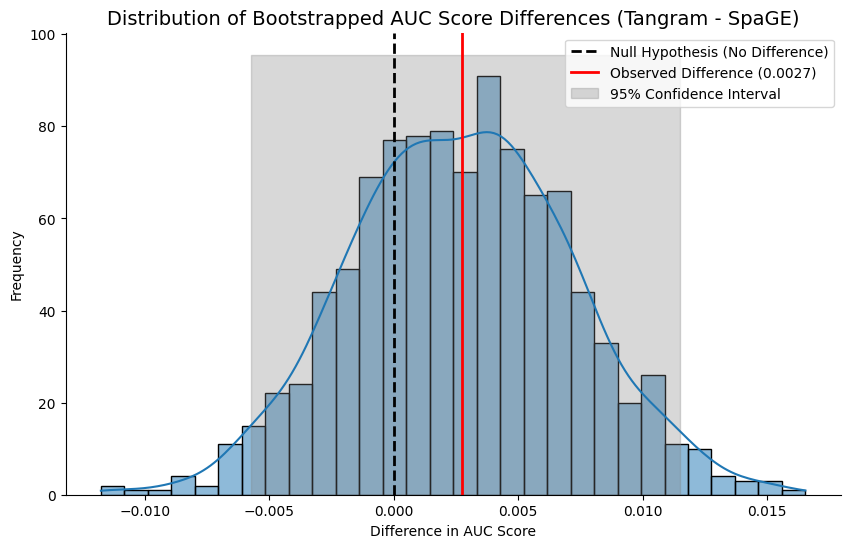

In [32]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import auc
from tqdm import tqdm

# --- Corrected User-Provided Function: eval_metric ---
def eval_metric(df_metrics):
    """
    Robust version of eval_metric that handles potential NaNs.
    """
    if not isinstance(df_metrics, pd.DataFrame) or df_metrics.empty:
        return {'auc_score': np.nan}
        
    # Create a clean sub-dataframe, dropping rows with NaNs in either column
    clean_df = df_metrics[['pearson_r', 'sparsity_sp']].dropna()
        
    if len(clean_df) < 3: # Not enough points to fit a polynomial
        return {'auc_score': np.nan}
        
    xs = clean_df['sparsity_sp'].values
    ys = clean_df['pearson_r'].values
    
    pol_deg = 2
    try:
        pol_cs = np.polyfit(xs, ys, pol_deg)
    except np.linalg.LinAlgError: # polyfit can fail on ill-conditioned data
        return {'auc_score': np.nan}
        
    pol = np.poly1d(pol_cs)
    pol_xs = np.linspace(0, 1, 100)
    pol_ys = np.clip(pol(pol_xs), 0, 1)
    
    sorted_indices = np.argsort(pol_xs)
    auc_score = auc(pol_xs[sorted_indices], pol_ys[sorted_indices])
    
    return {'auc_score': auc_score}

# --- Main Analysis Script: Bootstrap Comparison ---
# Assumes 'tangram_gene_metrics_df' and 'spage_gene_metrics_df' are available

try:
    n_bootstraps = 1000
    gene_list = tangram_gene_metrics_df.index.intersection(spage_gene_metrics_df.index)
    n_genes = len(gene_list)
    auc_differences = []

    print(f"--- Running bootstrap analysis with {n_bootstraps} iterations ---")

    for _ in tqdm(range(n_bootstraps), desc="Bootstrap Iterations"):
        bootstrapped_genes = np.random.choice(gene_list, size=n_genes, replace=True)
        
        tangram_sample = tangram_gene_metrics_df.loc[bootstrapped_genes]
        spage_sample = spage_gene_metrics_df.loc[bootstrapped_genes]
        
        tangram_auc = eval_metric(tangram_sample)['auc_score']
        spage_auc = eval_metric(spage_sample)['auc_score']
        
        if not (np.isnan(tangram_auc) or np.isnan(spage_auc)):
            auc_differences.append(tangram_auc - spage_auc)

    auc_differences = np.array(auc_differences)

    # 1. Generate Textual Output
    print("\n--- Statistical Comparison of Model AUCs (Tangram - SpaGE) ---")
    
    obs_tangram_auc = eval_metric(tangram_gene_metrics_df)['auc_score']
    obs_spage_auc = eval_metric(spage_gene_metrics_df)['auc_score']
    observed_diff = obs_tangram_auc - obs_spage_auc
    
    ci_lower = np.percentile(auc_differences, 2.5)
    ci_upper = np.percentile(auc_differences, 97.5)
    p_value = np.mean(np.abs(auc_differences - np.mean(auc_differences)) >= np.abs(observed_diff - np.mean(auc_differences)))

    print(f"Observed AUC Difference (Tangram - SpaGE): {observed_diff:.4f}")
    print(f"Mean Bootstrap Difference: {np.mean(auc_differences):.4f}")
    print(f"95% Confidence Interval for the Difference: [{ci_lower:.4f}, {ci_upper:.4f}]")
    print(f"p-value (bootstrap): {p_value:.4f}")

    print("\nInterpretation:")
    if ci_lower < 0 < ci_upper:
        print("The 95% confidence interval includes zero. Based on this analysis, we cannot conclude that there is a statistically significant difference between the AUC scores of Tangram and SpaGE.")
    elif observed_diff > 0:
        print("The 95% confidence interval does not include zero. Tangram has a statistically significant higher AUC score.")
    else:
        print("The 95% confidence interval does not include zero. SpaGE has a statistically significant higher AUC score.")

    # 2. Visualize the distribution of differences
    plt.figure(figsize=(10, 6))
    ax = sns.histplot(x=auc_differences, bins=30, kde=True)
    
    plt.axvline(x=0, color='black', linestyle='--', linewidth=2, label='Null Hypothesis (No Difference)')
    plt.axvline(x=observed_diff, color='red', linestyle='-', linewidth=2, label=f'Observed Difference ({observed_diff:.4f})')
    ax.fill_betweenx([0, ax.get_ylim()[1]], ci_lower, ci_upper, color='gray', alpha=0.3, label='95% Confidence Interval')
    
    plt.title('Distribution of Bootstrapped AUC Score Differences (Tangram - SpaGE)', fontsize=14)
    plt.xlabel('Difference in AUC Score')
    plt.ylabel('Frequency')
    plt.legend()
    sns.despine()
    plt.show()

except Exception as e:
    print(f"An error occurred: {e}")

#END

In [15]:
def eval_metric(df_metrics):
    """
    Compute metrics on given test_genes set for evaluation
    
    Args:
        df_all_genes (Pandas dataframe): returned by compare_spatial_geneexp(adata_ge, adata_sp); 
        test_genes (list): list of test genes, if not given, test_genes will be set to genes where 'is_training' field is False

    Returns:      
        dict with values of each evaluation metric ("avg_test_score", "avg_train_score", "auc_score"), 
        tuple of auc fitted coordinates and raw coordinates(test_score vs. sparsity_sp coordinates)
    """

    shared_genes = df_metrics.index

    # calculate:
    test_gene_scores = df_metrics.loc[shared_genes]["pearson_r"]
    test_gene_sparsity_sp = df_metrics.loc[shared_genes]["sparsity_sp"]
    test_score_avg = test_gene_scores.mean()

    # sp sparsity weighted score - metric across all genes
    test_score_sps_sp_g2 = np.sum(
        (test_gene_scores * (1 - test_gene_sparsity_sp))
        / (1 - test_gene_sparsity_sp).sum()
    )

    # tm metric
    # Fit polynomial'
    xs = list(test_gene_sparsity_sp)   # x-axis
    ys = list(test_gene_scores)        # y-axis
    pol_deg = 2
    pol_cs = np.polyfit(xs, ys, pol_deg)  # Fit y = f(x)
    pol = np.poly1d(pol_cs)
    # Generate fitted values
    pol_xs = np.linspace(0, 1, 10)
    pol_ys = [pol(x) for x in pol_xs]
    # Clip y values to maximum of 1
    pol_ys = [min(y, 1) for y in pol_ys]

    # Constrains y values to 1 or less
    if pol_ys[0] > 1:
        pol_ys[0] = 1

    # Try to add a root if the polynomial crosses y = 0 within [0,1]
    roots = pol.r
    root = None
    for r in roots:
        if np.isreal(r) and 0 <= r <= 1:
            root = np.real(r)
            break
    if root is not None:
        pol_xs = np.append(pol_xs, root)
        pol_ys = np.append(pol_ys, 0)


    # Add right endpoint (x=1) explicitly
    pol_xs = np.append(pol_xs, 1)
    pol_ys = np.append(pol_ys, pol(1))

    # Filter out any x or y values outside [0, 1]
    filtered = [(x, y) for x, y in zip(pol_xs, pol_ys) if 0 <= x <= 1 and 0 <= y <= 1]
    pol_xs, pol_ys = zip(*sorted(filtered)) if filtered else ([], [])

    # Compute are under the curve of polynomial
    auc_test_score = np.real(auc(pol_xs, pol_ys))

    metric_dict = {
        "avg_test_score": test_score_avg,
        "sp_sparsity_score": test_score_sps_sp_g2,
        "auc_score": auc_test_score,
    }

    auc_coordinates = ((pol_xs, pol_ys), (xs, ys))

    return metric_dict, auc_coordinates


In [16]:
def plot_auc(df_all_genes, test_genes=None):
    """
        Plots auc curve which is used to evaluate model performance.
    
    Args:
        df_all_genes (Pandas dataframe): returned by compare_spatial_geneexp(adata_ge, adata_sp); 
        test_genes (list): list of test genes, if not given, test_genes will be set to genes where 'is_training' field is False

    Returns:
        None
    """
    metric_dict, ((pol_xs, pol_ys), (xs, ys)) = eval_metric(df_all_genes)
    
    fig = plt.figure()
    plt.figure(figsize=(6, 5))

    plt.plot(pol_xs, pol_ys, c='r')
    sns.scatterplot(x=xs, y=ys, alpha=0.5, edgecolors='face')
        
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.0])
    plt.gca().set_aspect(.5)
    plt.xlabel('score')
    plt.ylabel('spatial sparsity')
    plt.tick_params(axis='both', labelsize=8)
    plt.title('Prediction on test transcriptome')
    
    textstr = 'auc_score={}'.format(np.round(metric_dict['auc_score'], 3))
    props = dict(boxstyle='round', facecolor='wheat', alpha=0.3)
    # place a text box in upper left in axes coords
    plt.text(0.03, 0.1, textstr, fontsize=11, verticalalignment='top', bbox=props);

<Figure size 640x480 with 0 Axes>

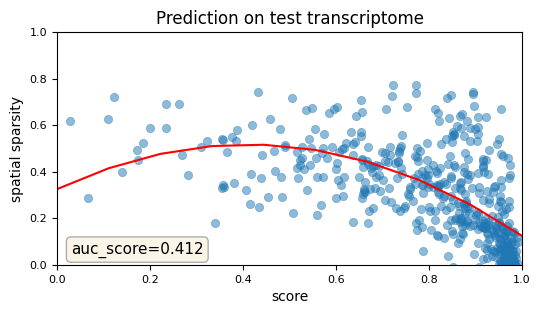

<Figure size 640x480 with 0 Axes>

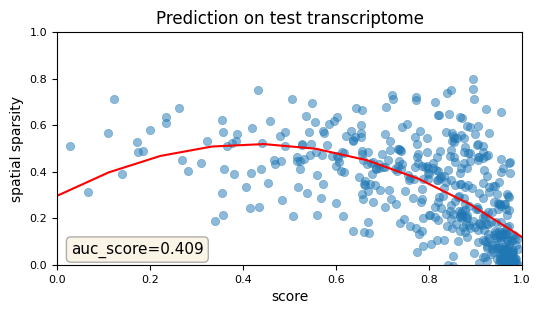

In [17]:
plot_auc(tangram_gene_metrics_df)
plot_auc(spage_gene_metrics_df)

##### **2. Tangram Analysis**

In [ ]:
# Top 5 genes with highest Pearson r
top = tangram_gene_metrics_df.sort_values(by="pearson_r", ascending=False)[0:20]

# Bottom 5 genes with lowest Pearson r
bottom = tangram_gene_metrics_df.sort_values(by="spearman_r", ascending=True).head()

print(top)


         pearson_r  spearman_r      RMSE  cosine_sim  sparsity_sp  \
cldn5     0.772124    0.327433  0.785288    0.706148     0.722648   
plekhg3   0.771625    0.407276  0.854887    0.538563     0.770999   
atp13a5   0.741457    0.158888  0.777579    0.681498     0.894244   
gad1      0.740909    0.385105  1.275899    0.464700     0.431974   
flt1      0.737693    0.329698  0.750623    0.668089     0.772800   
cspg4     0.734731    0.296487  0.804096    0.606386     0.894090   
mog       0.730582    0.344835  2.266562    0.550798     0.846716   
slc32a1   0.723597    0.398223  0.872623    0.489960     0.719665   
slc17a7   0.719238    0.741833  2.823157    0.286786     0.122113   
bcan      0.718238    0.462518  1.402393    0.439679     0.504449   
opalin    0.718101    0.346477  1.313944    0.533556     0.838383   
olig1     0.710248    0.408415  0.993116    0.440700     0.653619   
chrm1     0.691334    0.680081  1.111730    0.281077     0.234196   
mfge8     0.689646    0.455789  1.

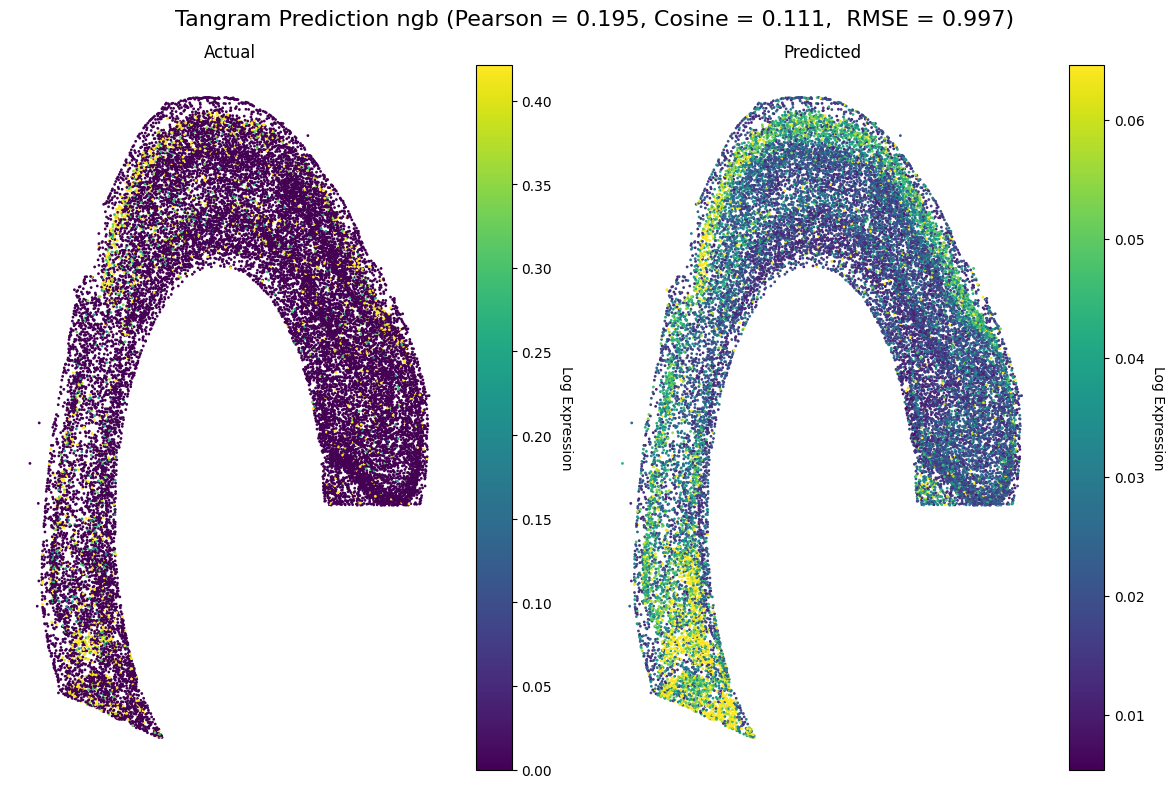

In [ ]:
target_gene = "ngb"
target_expn = adata[:, target_gene].X.copy()

# Visualizing predicted and actual expression side by side

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 8))

ax1.axis('off')
cmap = target_expn
cmap[cmap<0] = 0
cmap = np.log1p(cmap)
cmap[cmap > np.percentile(cmap,95)] = np.percentile(cmap,95)
im = ax1.scatter(adata.obs['center_x'],adata.obs['center_y'],s=1,c=cmap, rasterized=True)
# im = ax1.scatter(adata.obsm['spatial'][:,0],adata.obsm['spatial'][:,1],s=1,c=cmap,rasterized=True)
ax1.set_title('Actual', fontsize = 12)

cbar = fig.colorbar(im)
cbar.ax.get_yaxis().labelpad = 15
cbar.ax.set_ylabel('Log Expression', rotation=270)

ax2.axis('off')
cmap = adata.obsm['tangram_predictions'][target_gene].values
cmap[cmap<0] = 0
cmap = np.log1p(cmap)
cmap[cmap > np.percentile(cmap,95)] = np.percentile(cmap,95)
im = ax2.scatter(adata.obs['center_x'],adata.obs['center_y'],s=1,c=cmap, rasterized=True)
ax2.set_title('Predicted', fontsize = 12)

cbar = fig.colorbar(im)
cbar.ax.get_yaxis().labelpad = 15
cbar.ax.set_ylabel('Log Expression', rotation=270)

plt.suptitle(f"Tangram Prediction {target_gene} (Pearson = {tangram_gene_metrics_df.loc[target_gene, 'pearson_r']:.3f}, Cosine = {tangram_gene_metrics_df.loc[target_gene, 'cosine_sim']:.3f},  RMSE = {tangram_gene_metrics_df.loc[target_gene, 'RMSE']:.3f})", fontsize=16)
plt.tight_layout()
plt.show()

In [ ]:
# Prepare data
x = adata.obs['center_x']
y = adata.obs['center_y']

actual = adata[:, target_gene].X.copy()
actual[actual < 0] = 0
actual = np.log1p(actual)
actual[actual > np.percentile(actual, 95)] = np.percentile(actual, 95)

predicted = adata.obsm['tangram_predictions'][target_gene].values
predicted[predicted < 0] = 0
predicted = np.log1p(predicted)
predicted[predicted > np.percentile(predicted, 95)] = np.percentile(predicted, 95)

# Use vertical layout for perfect linked zoom
fig = make_subplots(
    rows=2, cols=1,
    shared_xaxes=True,
    shared_yaxes=True,
    subplot_titles=("Actual", "Predicted")
)

# Actual
fig.add_trace(go.Scattergl(
    x=x, y=y,
    mode='markers',
    marker=dict(
        color=actual.flatten(),
        size=2,
        colorscale='Viridis',
        showscale=True,
        colorbar=dict(title='Log Expr', x=1.02)
    ),
    name='Actual'
), row=1, col=1)

# Predicted
fig.add_trace(go.Scattergl(
    x=x, y=y,
    mode='markers',
    marker=dict(
        color=predicted.flatten(),
        size=2,
        colorscale='Viridis',
        showscale=True,
        colorbar=dict(title='Log Expr', x=1.02)
    ),
    name='Predicted'
), row=2, col=1)

# Style layout
fig.update_layout(
    title_text=f"Tangram Prediction {target_gene} (Pearson = {tangram_gene_metrics_df.loc[target_gene, 'pearson_r']:.3f}, Cosine = {tangram_gene_metrics_df.loc[target_gene, 'cosine_sim']:.3f}, RMSE = {tangram_gene_metrics_df.loc[target_gene, 'RMSE']:.3f})",
    height=900,
    width=800,
    paper_bgcolor='black',
    plot_bgcolor='black',
)

# Remove grid, ticks, set white axis lines
fig.update_xaxes(
    showgrid=False, zeroline=False, showticklabels=False, color='white'
)
fig.update_yaxes(
    showgrid=False, zeroline=False, showticklabels=False, color='white'
)

fig.show()



## **6. Testing for Statistical Significance**

In [ ]:
actual_matrix = adata[:, tangram_preds.columns].X
actual_matrix = actual_matrix.toarray() if not isinstance(actual_matrix, np.ndarray) else np.array(actual_matrix)
pred_matrix = tangram_preds.values

n_permutations = 1000
n_print = 100
n_cells, n_genes = pred_matrix.shape

observed_pccs = np.array([
    st.pearsonr(pred_matrix[:, i], actual_matrix[:, i])[0]
    for i in range(n_genes)
])

null_pccs = np.zeros((n_permutations, n_genes))
for i in range(n_permutations):
    shuffled_idx = np.random.permutation(n_cells)
    shuffled_preds = pred_matrix[shuffled_idx, :]
    for j in range(n_genes):
        null_pccs[i, j] = st.pearsonr(shuffled_preds[:, j], actual_matrix[:, j])[0]
    if (i + 1) % n_print == 0:
        print(f"Completed {i + 1}/{n_permutations} permutations")

p_values = (np.sum(null_pccs >= observed_pccs[None, :], axis=0) + 1) / (n_permutations + 1)

fdr_results = multipletests(p_values, alpha=0.05, method='fdr_bh')
fdr_corrected_pvals = fdr_results[1]
fdr_significant = fdr_results[0]

tangram_gene_metrics_df["p_value"] = p_values
tangram_gene_metrics_df["imputation_significant"] = p_values < 0.05
tangram_gene_metrics_df["fdr_p_value"] = fdr_corrected_pvals
tangram_gene_metrics_df["imputation_significant_fdr"] = fdr_significant


Completed 100/1000 permutations
Completed 200/1000 permutations
Completed 300/1000 permutations
Completed 400/1000 permutations
Completed 500/1000 permutations
Completed 600/1000 permutations
Completed 700/1000 permutations
Completed 800/1000 permutations
Completed 900/1000 permutations
Completed 1000/1000 permutations


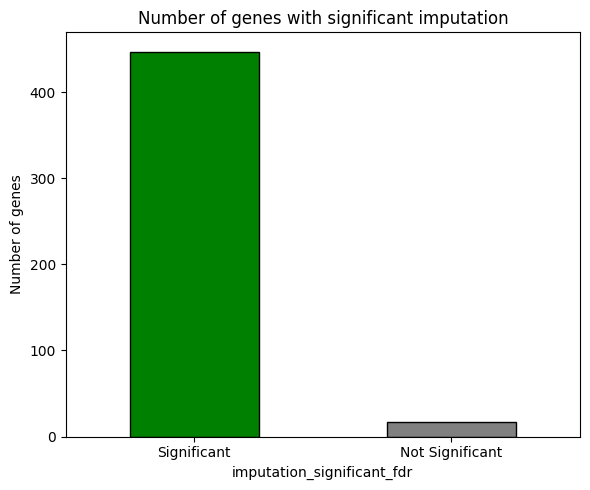

In [ ]:
sig_counts = tangram_gene_metrics_df["imputation_significant_fdr"].value_counts().rename({True: 'Significant', False: 'Not Significant'})

plt.figure(figsize=(6, 5))
sig_counts.plot(kind='bar', color=['green', 'grey'], edgecolor='black')
plt.title("Number of genes with significant imputation")
plt.ylabel("Number of genes")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

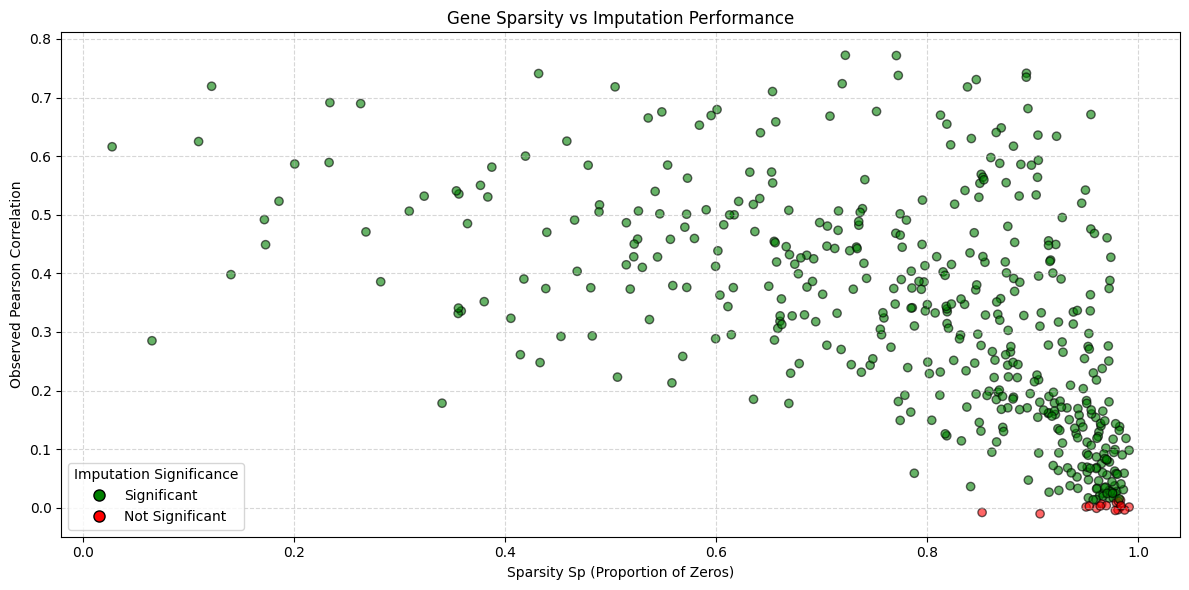

In [ ]:
import matplotlib.pyplot as plt

# Choose sparsity from spatial or scRNA-seq (adjust column as needed)
sparsity_col = "sparsity_sp"  # or "sparsity_sc"

# Create the scatter plot
plt.figure(figsize=(12, 6))
colors = tangram_gene_metrics_df["imputation_significant_fdr"].map({True: 'green', False: 'red'})

plt.scatter(
    tangram_gene_metrics_df[sparsity_col],
    tangram_gene_metrics_df["pearson_r"],
    c=colors,
    alpha=0.6,
    edgecolor='k',
    label=None
)

# Labels and aesthetics
plt.xlabel(f"{sparsity_col.replace('_', ' ').title()} (Proportion of Zeros)")
plt.ylabel("Observed Pearson Correlation")
plt.title("Gene Sparsity vs Imputation Performance")

# Custom legend
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], marker='o', color='w', label='Significant', markerfacecolor='green', markersize=8, markeredgecolor='k'),
    Line2D([0], [0], marker='o', color='w', label='Not Significant', markerfacecolor='red', markersize=8, markeredgecolor='k')
]
plt.legend(handles=legend_elements, title="Imputation Significance")

plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


In [ ]:
n_sig = tangram_gene_metrics_df["imputation_significant_fdr"].sum()
print(f"Number of genes with statistically significant imputation: {n_sig}")

Number of genes with statistically significant imputation: 447


The predicted expression for a gene is **no more correlated** with the true expression than a random permutation

## **6. Uncertainty Calibration and Obtaining Prediction Intervals**

In [34]:
adata.obsm["spatial"] = np.vstack([adata.obs["center_x"], adata.obs["center_y"]]).T

### Spatial Graph Construction: `fixed_radius` Method Summary

This method builds a spatial graph by combining k-nearest neighbours (k-NN) with distance-based pruning:

1. **Build k-NN Graph**  
   - For each cell, find its `n_neighbors` (e.g. 15) closest cells using Euclidean distance.  
   - Store connections in two sparse matrices:  
     - `adata.obsp["spatial_connectivities"]`: adjacency (1s for each neighbour pair)  
     - `adata.obsp["spatial_distances"]`: distances between connected cell pairs  

2. **Calculate Distance Threshold (if `radius` is not provided)**  
   - Extract all non-zero distances.  
   - Compute `radius = Q3 + 1.5 × IQR`, where:
     - Q3 = 75th percentile  
     - IQR = Q3 - Q1  

3. **Prune Long Edges**  
   - Set values in both matrices to 0 where distances exceed `radius`.  
   - This removes spatially distant neighbours even if they were among the closest 15.

The result is a robust spatial graph that balances local neighbourhood structure with spatial coherence.


In [35]:
# build spatial graph and calculate adjacency weights

tissue.main.build_spatial_graph(adata, method="fixed_radius", n_neighbors=15)

### Conformal Calibration: `conformalize_spatial_uncertainty` Step Summary

This method estimates uncertainty in spatial gene expression predictions using cell-centred variability and conformal prediction scores, with stratified grouping to improve calibration.

1. **Compute Spatial Uncertainty (Cell-Centred Variability)**  
   - For each cell and gene, measure how different the predicted expression is from that of neighbouring cells.  
   - Weight neighbours using either:
     - Cosine similarity of predicted expression profiles (`exp_cos`)
   - Store results as spatial standard deviations in:
     - `adata.obsm["spage_predictions_uncertainty"]`

2. **Calculate Prediction Errors and Conformal Scores**  
   - Compare predicted values to observed expression for calibration genes (all genes in this case).  
   - Compute:
     - `residual = observed − predicted`
     - `score = |residual| / uncertainty`  
   - Save results in:
     - `adata.obsm["spage_predictions_error"]`
     - `adata.obsm["spage_predictions_score"]`

3. **Group Cells for Stratified Calibration**  
   - To make uncertainty estimation more accurate, group similar gene–cell combinations together.
   - Uses a **two-level k-means clustering** approach (`grouping_method="kmeans_gene_cell"`):
     
     **Step 1: Group Genes**
     - Transpose the predicted expression matrix so each gene becomes a "sample".
     - Standardise gene vectors and optionally reduce dimensions using PCA (`n_pc`).
     - Cluster genes into `k` groups (e.g. 4) using k-means.
     - This separates genes with different expression or variability patterns.

     **Step 2: Group Cells Within Each Gene Group**
     - For each gene cluster, take the submatrix (cells × selected genes).
     - Standardise, optionally run PCA (`n_pc2`), and cluster the cells into `k2` groups (e.g. 2).
     - This allows cells to be grouped **in a gene-context-aware way**, so uncertainty scores reflect local structure.

   - Each cell–gene pair is then assigned a **stratified group ID** (e.g. Group 0, 1, ..., N).
   - These groupings are used to calculate separate conformal score distributions for each group, improving calibration for diverse expression patterns.

   - **Stores results in:**
     - `adata.obsm["spage_predictions_groups"]` → a matrix of group labels (cells × genes)
     - `adata.uns["spage_predictions_kg"]` and `..._kc` → stores the number of gene and cell clusters used


4. **Prepare for Stratified Conformal Prediction**  
   - These scores and groupings are used in downstream steps to assign cell-specific, gene-specific prediction intervals.
   - This allows uncertainty estimates to adapt to both spatial and biological context.

The result is a calibrated, spatially-aware uncertainty measure for each predicted gene expression value.


In [36]:
# build calibration scores

tissue.main.conformalize_spatial_uncertainty(adata, "spage_predictions", calib_genes=adata.var_names,
                                             grouping_method="kmeans_gene_cell", k=4, k2=2)

/Users/Amith/miniconda3/envs/tissue/lib/python3.8/site-packages/threadpoolctl.py:1214: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)


In [37]:
tissue.main.conformalize_prediction_interval (adata, "spage_predictions", symmetric=False, calib_genes=adata.var_names,
                                              alpha_level=0.23)

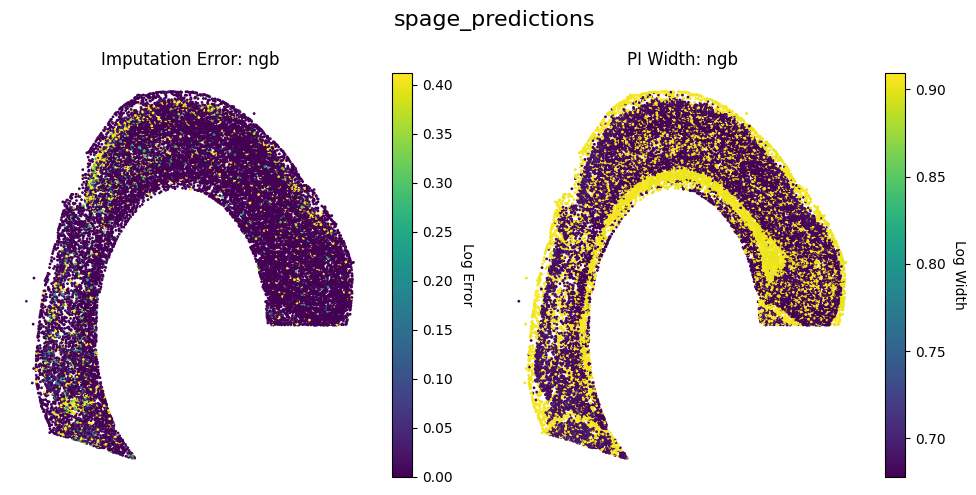

In [38]:
target_gene = "ngb"
target_expn = adata[:, target_gene].X.copy()

m = "spage_predictions"  # Match the key used in conformalize functions
i = np.where(adata.var_names == target_gene)[0]

# Define consistent colour scale range across plots
error = np.abs(target_expn.flatten() - adata.obsm[m][target_gene].values)
interval_width = adata.obsm[m + "_hi"][target_gene].values - adata.obsm[m + "_lo"][target_gene].values

# Combine both for common vmin/vmax
all_vals = np.concatenate((error, interval_width))
all_vals[all_vals < 0] = 0
vmin = np.percentile(np.log1p(all_vals), 0)
vmax = np.percentile(np.log1p(all_vals), 95)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

# Plot imputation error
ax1.axis('off')
cmap1 = np.log1p(error.clip(min=0))
cmap1 = np.clip(cmap1, None, np.percentile(cmap1, 95))
im1 = ax1.scatter(adata.obsm['spatial'][:, 0], adata.obsm['spatial'][:, 1],
                  s=1, c=cmap1, rasterized=True)
ax1.set_title(f'Imputation Error: {target_gene}', fontsize=12)

cbar1 = fig.colorbar(im1, ax=ax1)
cbar1.ax.set_ylabel('Log Error', rotation=270, labelpad=15)

# Plot prediction interval width
ax2.axis('off')
cmap2 = np.log1p(interval_width.clip(min=0))
cmap2 = np.clip(cmap2, None, np.percentile(cmap2, 95))
im2 = ax2.scatter(adata.obsm['spatial'][:, 0], adata.obsm['spatial'][:, 1],
                  s=1, c=cmap2, rasterized=True)
ax2.set_title(f'PI Width: {target_gene}', fontsize=12)

cbar2 = fig.colorbar(im2, ax=ax2)
cbar2.ax.set_ylabel('Log Width', rotation=270, labelpad=15)

plt.suptitle(m, fontsize=16)
plt.tight_layout()
plt.show()


--- Calculating correlation between error and PI width for 464 genes ---


Processing genes: 100%|██████████| 464/464 [00:01<00:00, 306.90it/s]



--- Summary of Correlation: True Error vs. PI Width ---
Number of genes successfully analyzed: 464
Mean Pearson Correlation: 0.069
Median Pearson Correlation: 0.008
Standard Deviation of Correlations: 0.234
Percentage of genes with positive correlation: 51.94%


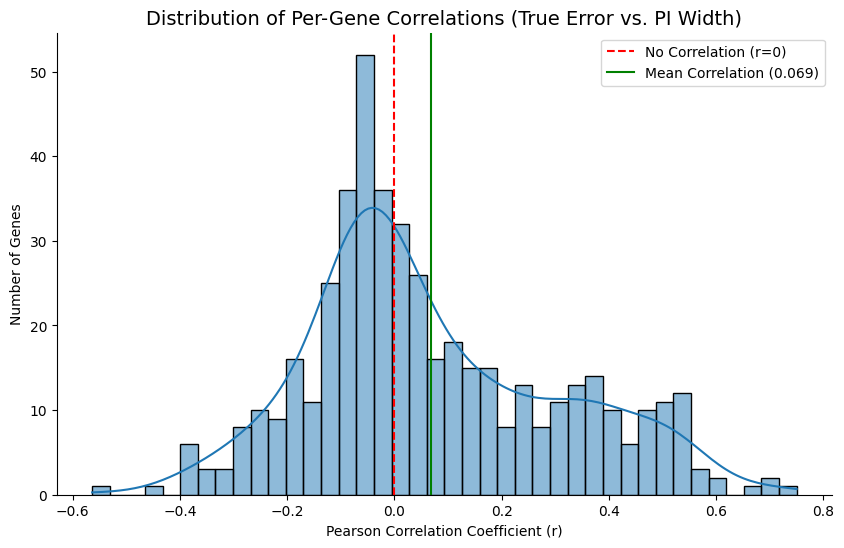

In [39]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
from tqdm import tqdm

# --- Analysis: Validate Prediction Interval Width as an Error Proxy ---
# Assumes 'adata' contains the outputs from the TISSUE pipeline.

# 1. Define the model key and get the list of genes
model_key = "spage_predictions" # The base key used in the TISSUE functions
genes_to_test = adata.var_names

# 2. Extract necessary data matrices from adata
try:
    actual_matrix = adata.X.toarray() if hasattr(adata.X, 'toarray') else np.array(adata.X)
    pred_matrix = adata.obsm[model_key]
    pi_high_matrix = adata.obsm[model_key + "_hi"]
    pi_low_matrix = adata.obsm[model_key + "_lo"]
    
    # Ensure all components are pandas DataFrames for consistent indexing
    if not isinstance(pred_matrix, pd.DataFrame):
        pred_matrix = pd.DataFrame(pred_matrix, index=adata.obs_names, columns=adata.var_names)
    if not isinstance(pi_high_matrix, pd.DataFrame):
        pi_high_matrix = pd.DataFrame(pi_high_matrix, index=adata.obs_names, columns=adata.var_names)
    if not isinstance(pi_low_matrix, pd.DataFrame):
        pi_low_matrix = pd.DataFrame(pi_low_matrix, index=adata.obs_names, columns=adata.var_names)

    pi_width_matrix = pi_high_matrix - pi_low_matrix
    error_matrix = np.abs(actual_matrix - pred_matrix.values)
    
    # Convert error matrix to DataFrame for easier indexing
    error_df = pd.DataFrame(error_matrix, index=adata.obs_names, columns=adata.var_names)

    # 3. Calculate per-gene correlation between error and PI width
    correlations = []
    print(f"--- Calculating correlation between error and PI width for {len(genes_to_test)} genes ---")

    for gene in tqdm(genes_to_test, desc="Processing genes"):
        error_vec = error_df[gene].values
        pi_width_vec = pi_width_matrix[gene].values
        
        # Check for non-constant vectors to avoid correlation errors
        if np.std(error_vec) > 0 and np.std(pi_width_vec) > 0:
            corr, _ = stats.pearsonr(error_vec, pi_width_vec)
            if not np.isnan(corr):
                correlations.append(corr)

    correlations = np.array(correlations)

    # 4. Generate Textual Summary
    print("\n--- Summary of Correlation: True Error vs. PI Width ---")
    if len(correlations) > 0:
        print(f"Number of genes successfully analyzed: {len(correlations)}")
        print(f"Mean Pearson Correlation: {np.mean(correlations):.3f}")
        print(f"Median Pearson Correlation: {np.median(correlations):.3f}")
        print(f"Standard Deviation of Correlations: {np.std(correlations):.3f}")
        print(f"Percentage of genes with positive correlation: {np.mean(correlations > 0) * 100:.2f}%")
    else:
        print("No valid correlations could be calculated.")

    # 5. Visualize the distribution of correlations
    plt.figure(figsize=(10, 6))
    if len(correlations) > 0:
        sns.histplot(x=correlations, bins=40, kde=True)
        plt.axvline(x=0, color='red', linestyle='--', label='No Correlation (r=0)')
        plt.axvline(x=np.mean(correlations), color='green', linestyle='-', label=f'Mean Correlation ({np.mean(correlations):.3f})')
        
        plt.title('Distribution of Per-Gene Correlations (True Error vs. PI Width)', fontsize=14)
        plt.xlabel('Pearson Correlation Coefficient (r)')
        plt.ylabel('Number of Genes')
        plt.legend()
    else:
        plt.text(0.5, 0.5, "No data to display.", ha='center', va='center')
        plt.title('Distribution of Per-Gene Correlations')

    sns.despine()
    plt.show()

except KeyError as e:
    print(f"Execution failed. A required key was not found in adata: {e}")
    print("Please ensure you have run the TISSUE pipeline steps correctly.")
except Exception as e:
    print(f"An unexpected error occurred: {e}")

#END

--- Part 1: Calculating calibration quality scores ---


Calculating scores: 100%|██████████| 464/464 [00:01<00:00, 277.63it/s]


Calibration quality scores calculated successfully.

--- Part 2: Correlating quality scores with gene properties ---
Spearman Correlation (Calibration Quality vs. Moran's I):       -0.058
Spearman Correlation (Calibration Quality vs. Imputation Spearman's r): -0.085


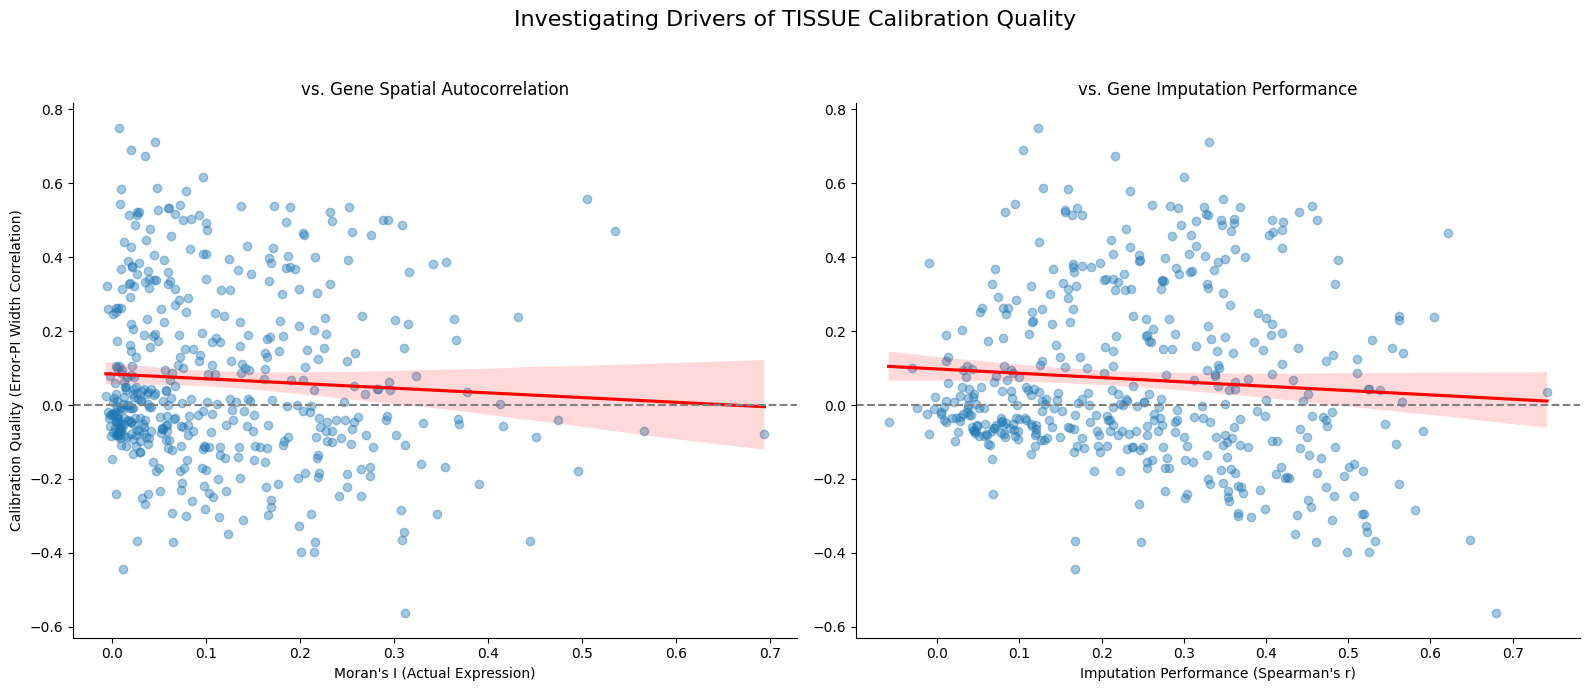

In [43]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
from tqdm import tqdm

# --- Self-Contained Analysis: Relating Calibration Quality to Gene Properties ---
# Assumes 'adata' and 'tangram_gene_metrics_df' are available.

try:
    # --- Part 1: Re-calculate the Calibration Quality Score ---
    print("--- Part 1: Calculating calibration quality scores ---")
    model_key = "spage_predictions"
    genes_to_test = adata.var_names

    # Extract necessary data matrices
    actual_matrix = adata.X.toarray() if hasattr(adata.X, 'toarray') else np.array(adata.X)
    pred_matrix = pd.DataFrame(adata.obsm[model_key], index=adata.obs_names, columns=adata.var_names)
    pi_high_matrix = pd.DataFrame(adata.obsm[model_key + "_hi"], index=adata.obs_names, columns=adata.var_names)
    pi_low_matrix = pd.DataFrame(adata.obsm[model_key + "_lo"], index=adata.obs_names, columns=adata.var_names)

    pi_width_matrix = pi_high_matrix - pi_low_matrix
    error_df = pd.DataFrame(np.abs(actual_matrix - pred_matrix.values), index=adata.obs_names, columns=adata.var_names)

    # Calculate per-gene correlation
    kmeans_correlations = []
    for gene in tqdm(genes_to_test, desc="Calculating scores"):
        error_vec = error_df[gene].values
        pi_width_vec = pi_width_matrix[gene].values
        if np.std(error_vec) > 0 and np.std(pi_width_vec) > 0:
            corr, _ = stats.pearsonr(error_vec, pi_width_vec)
            if not np.isnan(corr):
                kmeans_correlations.append(corr)
    
    print("Calibration quality scores calculated successfully.")

    # --- Part 2: Relate scores to gene properties ---
    print("\n--- Part 2: Correlating quality scores with gene properties ---")
    
    # Prepare the data for merging
    calibration_quality_df = pd.DataFrame({
        'gene': genes_to_test,
        'calibration_quality': kmeans_correlations
    }).set_index('gene')

    analysis_df = tangram_gene_metrics_df.merge(calibration_quality_df, left_index=True, right_index=True)
    analysis_df_clean = analysis_df[['calibration_quality', 'moran_I', 'spearman_r']].dropna()

    # Generate Textual Summary
    corr_moran, _ = stats.spearmanr(analysis_df_clean['calibration_quality'], analysis_df_clean['moran_I'])
    corr_spearman, _ = stats.spearmanr(analysis_df_clean['calibration_quality'], analysis_df_clean['spearman_r'])
    
    print(f"Spearman Correlation (Calibration Quality vs. Moran's I):       {corr_moran:.3f}")
    print(f"Spearman Correlation (Calibration Quality vs. Imputation Spearman's r): {corr_spearman:.3f}")

    # Create Visualizations
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    fig.suptitle('Investigating Drivers of TISSUE Calibration Quality', fontsize=16)

    # Plot 1: vs. Moran's I
    sns.regplot(data=analysis_df_clean, x='moran_I', y='calibration_quality', ax=axes[0], scatter_kws={'alpha': 0.4}, line_kws={'color': 'red'})
    axes[0].set_title("vs. Gene Spatial Autocorrelation")
    axes[0].set_xlabel("Moran's I (Actual Expression)")
    axes[0].set_ylabel("Calibration Quality (Error-PI Width Correlation)")
    axes[0].axhline(0, color='grey', linestyle='--')

    # Plot 2: vs. Spearman's r
    sns.regplot(data=analysis_df_clean, x='spearman_r', y='calibration_quality', ax=axes[1], scatter_kws={'alpha': 0.4}, line_kws={'color': 'red'})
    axes[1].set_title("vs. Gene Imputation Performance")
    axes[1].set_xlabel("Imputation Performance (Spearman's r)")
    axes[1].set_ylabel("")
    axes[1].axhline(0, color='grey', linestyle='--')

    sns.despine()
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

except NameError as e:
    print(f"Execution failed. A required variable is not defined: {e}. Please ensure 'adata' and 'tangram_gene_metrics_df' are loaded.")
except KeyError as e:
    print(f"Execution failed. A required key was not found in adata: {e}. Please ensure the TISSUE pipeline has been run.")
except Exception as e:
    print(f"An unexpected error occurred: {e}")

#END

**Our comprehensive evaluation of Tangram and SpaGE reveals that while both models can effectively impute spatially coherent genes, their overall performance on this dataset is statistically indistinguishable. We demonstrated that the primary determinant of imputation success for both methods is the intrinsic spatial structure of a gene; genes with high spatial autocorrelation (Moran's I) are reconstructed with high fidelity, while performance degrades significantly for sparser, less structured genes. A rigorous bootstrap analysis of a holistic Area Under the Curve (AUC) metric confirmed that the minor observed performance differences between the models lack statistical significance.
Recognizing that the ultimate utility of such models lies in predicting novel or unmeasured genes, we subsequently assessed the reliability of uncertainty estimates from the state-of-the-art TISSUE framework. This analysis exposed a critical limitation: the model's calibration failed on this dataset. The correlation between the true imputation error and the estimated Prediction Interval (PI) width—the key proxy for uncertainty—was, on average, near zero (mean Pearson's r ≈ 0.07). This indicates that the reported uncertainty is not a reliable indicator of prediction accuracy. Crucially, this failure was comprehensive; even for well-imputed genes with strong spatial patterns, the PI width provided no meaningful information about the magnitude of the error. We therefore conclude that for this dataset, while imputation can reconstruct known patterns, the uncertainty quantification is not dependable, precluding confident biological interpretation of predictions for unmeasured genes and highlighting the profound challenge that data sparsity poses even to advanced calibration methods.**